Clean Text: artificial intelligence is changing the world it helps people solve difficult problems
ai is used in healthcare education and transportation machine learning allows computers to learn from data
many companies use ai to improve their services artificial intelligence will play an important role in the future
Sentences: ['Artificial intelligence is changing the world.', 'It helps people solve difficult problems.', 'AI is used in healthcare, education, and transportation.', 'Machine learning allows computers to learn from data.', 'Many companies use AI to improve their services.', 'Artificial intelligence will play an important role in the future.']
Split: ['artificial', 'intelligence', 'is', 'changing', 'the', 'world', 'it', 'helps', 'people', 'solve', 'difficult', 'problems', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'and', 'transportation', 'machine', 'learning', 'allows', 'computers', 'to', 'learn', 'from', 'data', 'many', 'companies', 'use', 'ai', 'to', 'improve

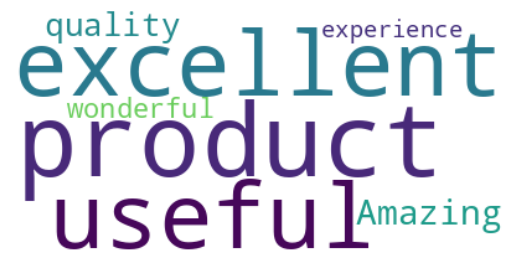

Line 1 : intelligence is changing world machine machine machine
Line 2 : learning helps computers computers computers computers computers
Line 3 : computers computers computers computers computers and improves


In [1]:
# Q1
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist
from nltk.stem import PorterStemmer, WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import numpy as np

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

text = """Artificial intelligence is changing the world. It helps people solve difficult problems.
AI is used in healthcare, education, and transportation. Machine learning allows computers to learn from data.
Many companies use AI to improve their services. Artificial intelligence will play an important role in the future."""

clean = re.sub(r'[^\w\s]', '', text.lower())
words_split = clean.split()
words_nltk = word_tokenize(clean)
sentences = sent_tokenize(text)
stop_words = set(stopwords.words('english'))
filtered = [w for w in words_nltk if w not in stop_words]

print("Clean Text:", clean)
print("Sentences:", sentences)
print("Split:", words_split)
print("NLTK Tokens:", words_nltk)
print("Difference:", len(words_split), len(words_nltk))
print("Without Stopwords:", filtered)
print("Frequency:", FreqDist(filtered).most_common())

# Q2
words = re.findall(r'[a-zA-Z]+', text.lower())
filtered = [w for w in words if w not in stop_words]

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

stemmed = [stemmer.stem(w) for w in filtered]
lemmatized = [lemmatizer.lemmatize(w) for w in filtered]

print("Words:", words)
print("Without Stopwords:", filtered)
print("Stemmed:", stemmed)
print("Lemmatized:", lemmatized)
print("Stemming is faster but may produce incomplete words.")
print("Lemmatization produces meaningful dictionary words.")

# Q3
texts = [
    "Artificial intelligence improves healthcare and medical diagnosis",
    "Machine learning helps computers analyze large datasets",
    "Python programming is useful for data science and artificial intelligence"
]

bow = CountVectorizer()
X_bow = bow.fit_transform(texts)

print("BoW Features:", bow.get_feature_names_out())
print("BoW Matrix:\n", X_bow.toarray())

tfidf = TfidfVectorizer()
Y = tfidf.fit_transform(texts)

print("TF-IDF Features:", tfidf.get_feature_names_out())
print("TF-IDF Matrix:\n", Y.toarray())

words = tfidf.get_feature_names_out()

for i in range(len(texts)):
    scores = Y.toarray()[i]
    top = np.argsort(scores)[::-1][:3]
    print("Text", i+1, "Top Keywords:", [(words[j], round(scores[j], 3)) for j in top])

# Q4
text1 = """Artificial intelligence helps machines learn from data.
AI is used in healthcare and education.
Machine learning improves predictions.
AI systems automate complex tasks.
Artificial intelligence supports decision making."""

text2 = """Blockchain is a technology for storing secure data.
It uses distributed networks to record transactions.
Blockchain improves transparency and security.
This technology is used in digital finance.
Blockchain systems protect records from modification."""

words1 = set(re.findall(r'[a-z]+', text1.lower()))
words2 = set(re.findall(r'[a-z]+', text2.lower()))

print("Tokens 1:", words1)
print("Tokens 2:", words2)

jaccard = len(words1 & words2) / len(words1 | words2)
print("Jaccard Similarity:", jaccard)

tfidf = TfidfVectorizer()
vectors = tfidf.fit_transform([text1, text2])
cosine = cosine_similarity(vectors[0:1], vectors[1:2])

print("Cosine Similarity:", cosine[0][0])
print("Jaccard measures common words.")
print("Cosine uses TF-IDF weights and gives better insights into important shared terms.")

# Q5
reviews = [
    "This product is excellent and very useful.",
    "The service was terrible and disappointing.",
    "The product is average and works normally.",
    "Amazing quality and wonderful experience."
]

positive = []

for review in reviews:
    blob = TextBlob(review)
    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity

    if polarity > 0:
        sentiment = "Positive"
        positive.append(review)
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print("Review:", review)
    print("Polarity:", polarity)
    print("Subjectivity:", subjectivity)
    print("Sentiment:", sentiment)

if positive:
    cloud = WordCloud(background_color="white").generate(" ".join(positive))
    plt.imshow(cloud, interpolation="bilinear")
    plt.axis("off")
    plt.show()

# Q6
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

text = """Artificial intelligence is changing the world of technology.
Machine learning helps computers learn from data and make predictions.
Artificial intelligence is useful in healthcare education and transportation.
Machine learning improves the performance of intelligent systems.
Computers can recognize patterns and solve complex problems.
Artificial intelligence makes everyday tasks easier and faster.
Many companies use machine learning to improve their services.
Technology is growing rapidly and creating new opportunities.
Artificial intelligence helps doctors diagnose diseases accurately.
Machine learning is important for developing smart applications.
Students learn artificial intelligence to understand modern technology.
The future of technology depends on intelligent systems.
Artificial intelligence and machine learning are transforming our lives.
Smart machines can process information and support human decisions.
Learning new technologies helps people develop useful skills."""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

tokens = tokenizer.texts_to_sequences([text])[0]
sequences = []

for i in range(1, len(tokens)):
    sequences.append(tokens[:i+1])

max_len = max(len(s) for s in sequences)
sequences = pad_sequences(sequences, maxlen=max_len)

X = sequences[:, :-1]
y = sequences[:, -1]

vocab_size = len(tokenizer.word_index) + 1

model = Sequential([
    Embedding(vocab_size, 10),
    LSTM(50),
    Dense(vocab_size, activation='softmax')
])

model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.fit(X, y, epochs=100, verbose=0)

seed_text = "artificial intelligence"

for line in range(3):
    generated = []
    for i in range(7):
        seq = tokenizer.texts_to_sequences([seed_text])[0]
        seq = pad_sequences([seq], maxlen=X.shape[1])
        predicted = np.argmax(model.predict(seq, verbose=0), axis=-1)[0]
        word = tokenizer.index_word.get(predicted, "")
        if word:
            seed_text += " " + word
            generated.append(word)
    print("Line", line+1, ":", " ".join(generated))